In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from compcats.models import resnet50_imagenet1kv2
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/frontiers_poster'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR

froi = 'FFA'
pref_category = 'faces'
tthreshold = 2
model_localizer = 'grillspector'
subject = 2
subset = 515

plot_dir = f'{PLOTS_DIR}'
os.makedirs(plot_dir, exist_ok=True)

# Load ResNet50-ImageNet
model = resnet50_imagenet1kv2.get_model()

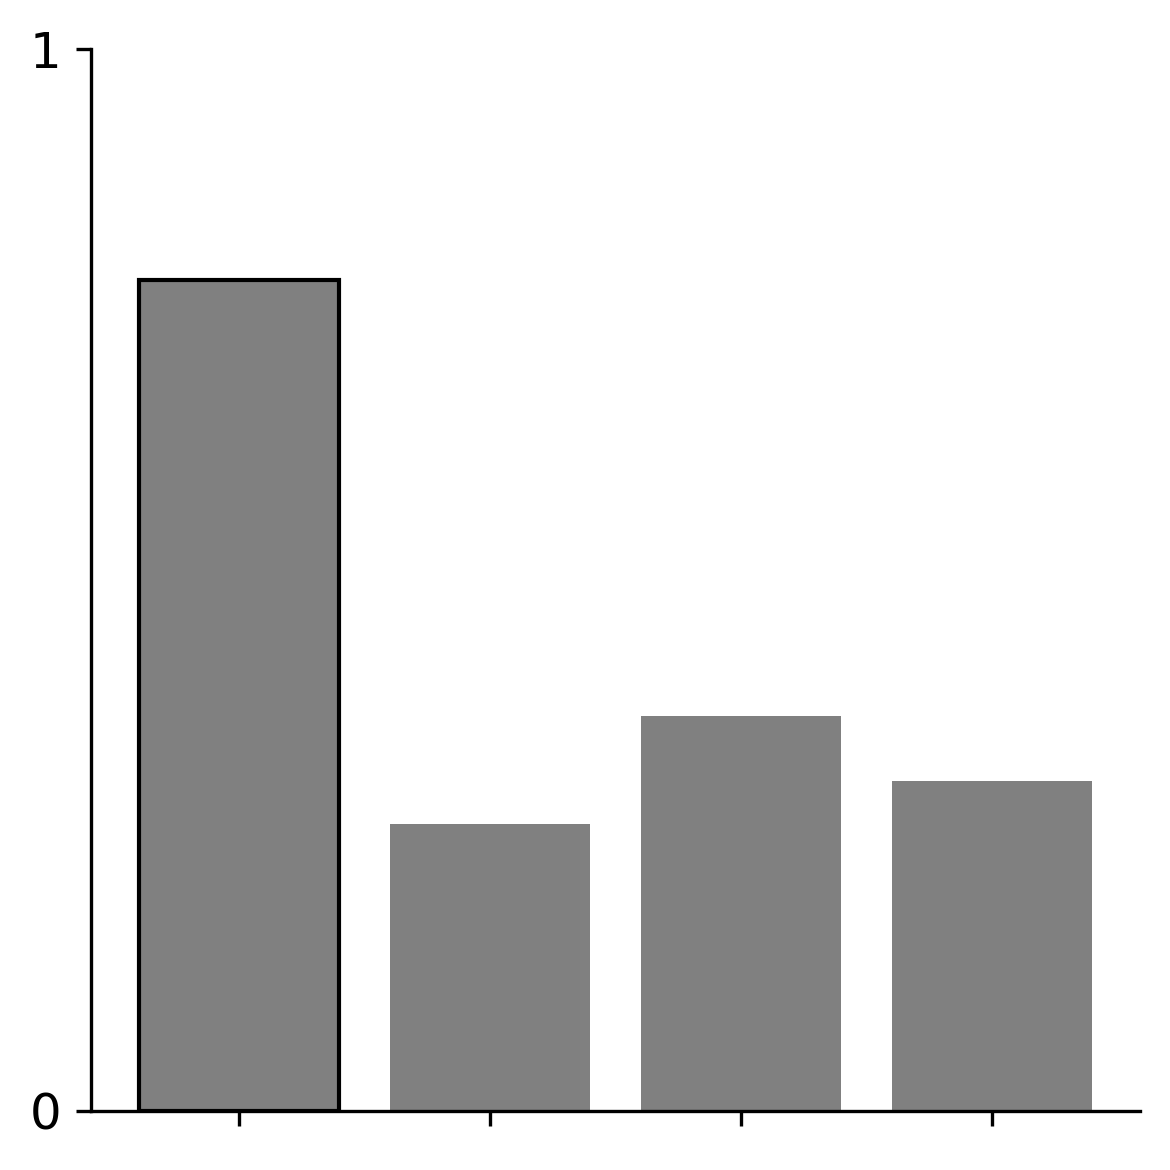

In [10]:
# Konkle FBSO
ko_acts = model_utils.get_dataset_activations(
    MODELS_DIR, KONKLE_LOCALIZER_DIR, \
    model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='localizer', localizer_type='konkle', \
    froi=froi, tthreshold=tthreshold, \
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
)
ko_acts_univariate = {k: v.mean(axis=-1) for k, v in ko_acts.items()}

# Prepare data for plotting with z-scoring
categories = list(ko_acts_univariate.keys())

# Reorder categories and rename 'places' to 'scenes'
# category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
# ordered_categories = ['faces', 'bodies', 'places', 'objects', 'characters', 'scrambledobjects']
ordered_categories = ['faces', 'scenes', 'bodies', 'objects']
# display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

# Get all activations and compute overall mean and std for z-scoring
all_vals = torch.cat([ko_acts_univariate[cat] for cat in categories])
overall_mean = all_vals.mean().cpu().numpy()
overall_std = all_vals.std().cpu().numpy()

# Compute z-scored medians and SEMs for the ordered categories
z_medians = [torch.median(ko_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
z_sems = [torch.std(ko_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(ko_acts_univariate[cat])) for cat in ordered_categories]
z_sems = None
# z_medians = [(torch.median(ko_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
# z_sems = [(torch.std(ko_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(ko_acts_univariate[cat]))) / overall_std for cat in ordered_categories]

# Set up the plot
plt.figure(figsize=(4, 4), dpi=300)
bar_positions = np.arange(len(ordered_categories))
# bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
#                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, color='gray')

# Highlight the preferred category
for i, cat in enumerate(ordered_categories):
    if cat == pref_category:
        # bars[i].set_color('coral')
        bars[i].set_color('gray')
        bars[i].set_edgecolor('black')
        bars[i].set_linewidth(1)

# Add horizontal line at z=0
# plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)

# Add labels and title
# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# plt.xlabel('Categories', fontsize=12)
# plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
# plt.title(f'ResNet50 z-scored Univariate Responses of face-selective units', fontsize=14)
# plt.xticks(bar_positions, [cat.capitalize() for cat in ordered_categories], rotation=45)
# plt.yticks([0, 1, 2], [0, 1, 2], fontsize=12)
plt.yticks([0, 1], [0, 1], fontsize=12)
plt.xticks(bar_positions, [])
plt.tight_layout()

# plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.png', dpi=300, bbox_inches='tight', transparent=True)
# plt.show()

In [2]:
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='nsd', subset=subset, froi=froi, tthreshold=tthreshold,
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
).mean(axis=-1)
model_data = model_data.cpu().numpy()
model_data_zscore = (model_data - np.mean(model_data)) / np.std(model_data)

subject_data1, _ = nsd.get_betas(
    NSD_DIR, subject, froi=froi, tthreshold=tthreshold, subset=subset, voxels=False
)
subject_data1 = subject_data1.cpu().numpy()
subject_data1_zscore = (subject_data1 - np.mean(subject_data1)) / np.std(subject_data1)

subject_data2, _ = nsd.get_betas(
    NSD_DIR, 5, froi=froi, tthreshold=tthreshold, subset=subset, voxels=False
)
subject_data2 = subject_data2.cpu().numpy()
subject_data2_zscore = (subject_data2 - np.mean(subject_data2)) / np.std(subject_data2)

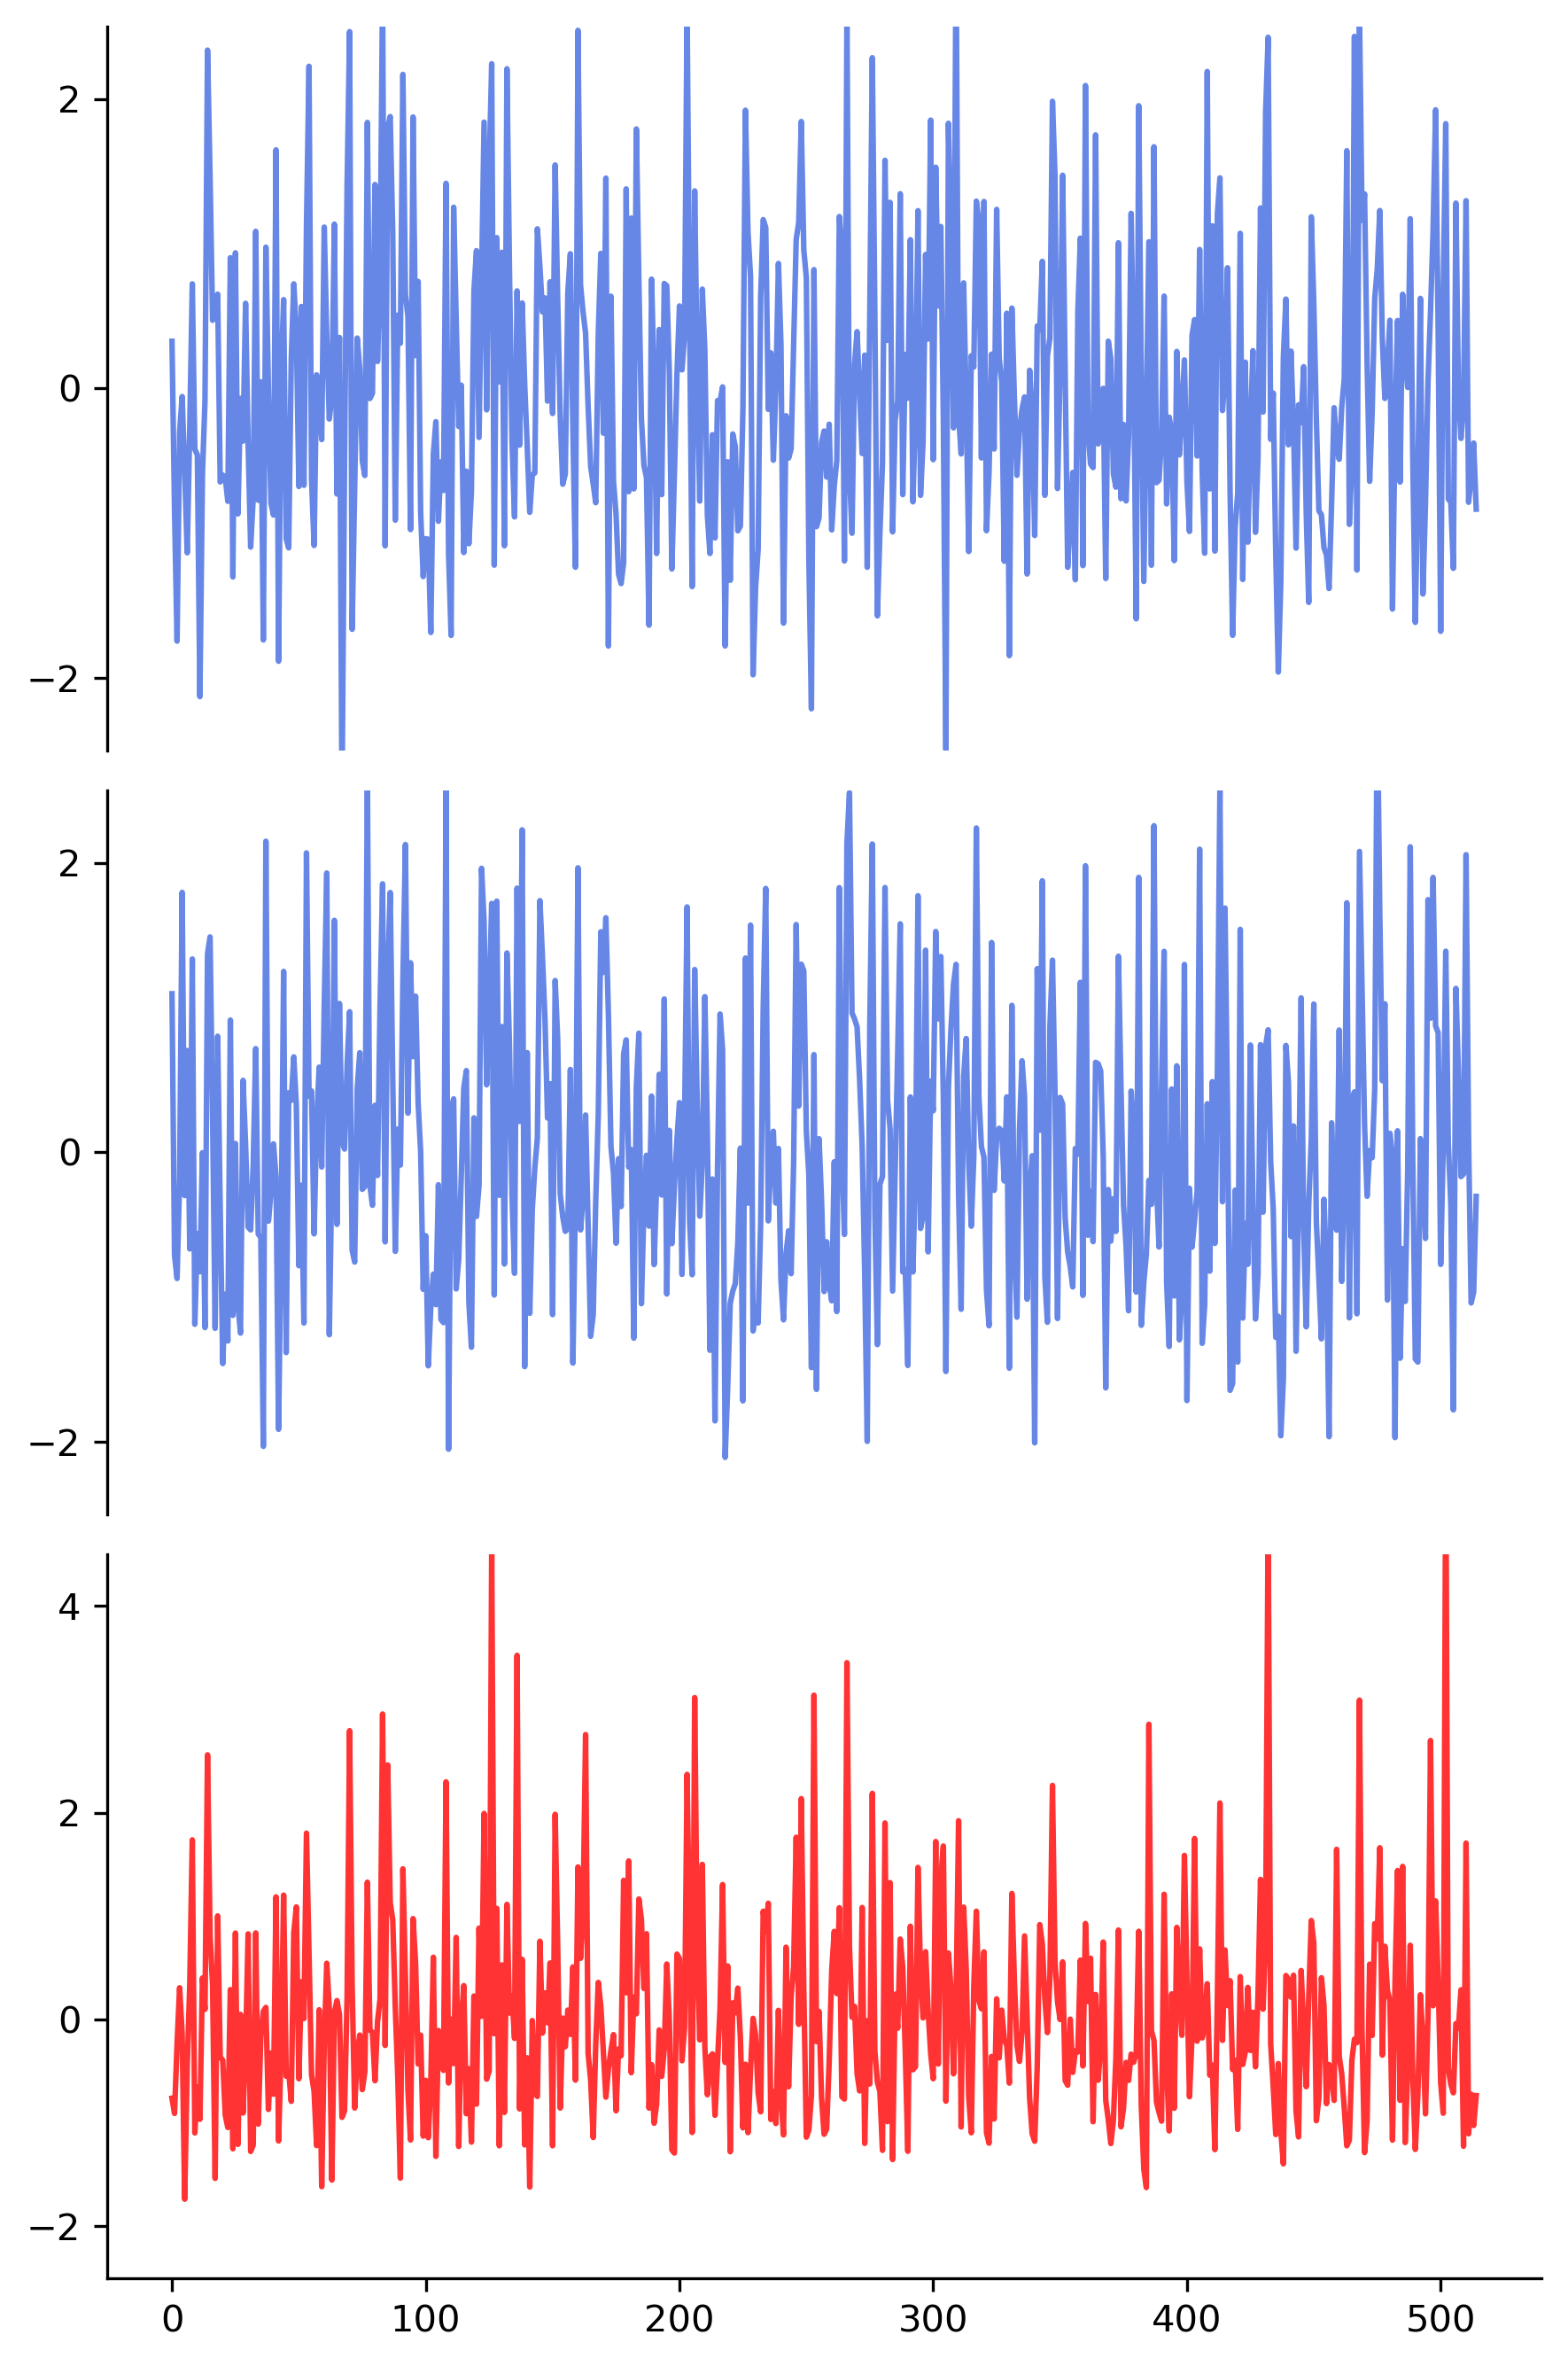

In [3]:
# Subject sorted univariate responses
# plt.figure(figsize=(10, 6), dpi=300)
fig, axes = plt.subplots(3, 1, figsize=(6, 9), dpi=300)

# Sort the data according to subject_zscore for better visualization
# sorted_indices = np.argsort(subject_zscore)[::-1]
# sorted_subject_zscore = subject_zscore[sorted_indices]
# sorted_model_zscore = model_zscore[sorted_indices]

# Plot the data
axes[0].plot(subject_data1_zscore, color='royalblue', alpha=0.8)
axes[1].plot(subject_data2_zscore, color='royalblue', alpha=0.8)
axes[2].plot(model_data_zscore, color='red', alpha=0.8)
# axes[0].plot(subject_data1, color='royalblue', alpha=0.8)
# axes[1].plot(subject_data2, color='royalblue', alpha=0.8)
# axes[2].plot(model_data, color='red', alpha=0.8)

# Plot the data
# plt.plot(subject_zscore, color='royalblue', label='Human', alpha=0.8)
# plt.plot(model_zscore, color='red', label='ResNet50', alpha=0.8)

# Add labels and title
# plt.xlabel('Sorted Stimuli Index', fontsize=12)
# plt.ylabel('Voxel/Unit-averaged Responses', fontsize=12)
# plt.title(f'Subject {subject} vs ResNet50 Responses in {froi}', fontsize=14)

# Add legend
# plt.legend(loc='upper right', fontsize=12)

# Remove top and right spines
for ax_idx in range(len(axes.flatten())):
    axes[ax_idx].spines['top'].set_visible(False)
    axes[ax_idx].spines['right'].set_visible(False)
    if ax_idx < 2:
        axes[ax_idx].spines['bottom'].set_visible(False)
        axes[ax_idx].set_xticks([])
    # axes[ax_idx].spines['left'].set_visible(False)
# plt.gca().spines['top'].set_visible(False)
# plt.gca().spines['right'].set_visible(False)
# Set y-ticks for each subplot
axes[0].set_yticks([-2, 0, 2])
axes[0].set_ylim(-2.5, 2.5)
axes[1].set_yticks([-2, 0, 2])
axes[1].set_ylim(-2.5, 2.5)
axes[2].set_yticks([-2, 0, 2, 4])
axes[2].set_ylim(-2.5, 4.5)

# Add y-axis labels
# axes[0].set_ylabel('Model', fontsize=10)
# axes[1].set_ylabel('Subject 2', fontsize=10)
# axes[2].set_ylabel('Subject 5', fontsize=10)

# Tight layout
plt.tight_layout()

# Save the plot
plt.savefig(f'{plot_dir}/model_human_human_responses.pdf', dpi=300, bbox_inches='tight')

# Show the plot
# plt.show()